# Underwater waste detection

Install required libraries

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

Dataset paths

In [ ]:
# Import libraries
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

from collections import Counter
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Dataset paths
base_dir = '/content/drive/MyDrive/dataset/material_version'

train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')

train_json = os.path.join(base_dir, 'instances_train_trashcan.json')
val_json = os.path.join(base_dir, 'instances_val_trashcan.json')

# Cropped image paths
crop_dir = '/content/drive/MyDrive/dataset/waste_classification/train'

val_crop_dir = '/content/drive/MyDrive/dataset/waste_classification/val'

# New balanced dataset paths
balanced_dir = '/content/drive/MyDrive/dataset/waste_classification_balanced'

balanced_train_dir = os.path.join(balanced_dir, 'train')
balanced_val_dir = os.path.join(balanced_dir, 'val')

print("Dataset paths successfully created.")


Dataset paths successfully created.


Load the COCO annotation files

In [ ]:
# Load training annotations

with open(train_json, 'r') as file:
    train_data = json.load(file)

# Load validation annotations

with open(val_json, 'r') as file:
    val_data = json.load(file)

print("Training images:", len(train_data['images']))
print("Validation images:", len(val_data['images']))

print("Training annotations:", len(train_data['annotations']))
print("Validation annotations:", len(val_data['annotations']))


Training images: 6008
Validation images: 1204
Training annotations: 9741
Validation annotations: 2595


Select the eight waste categories

In [ ]:
# Display available classes

categories_df = pd.DataFrame(train_data['categories'])

display(categories_df[['name']])

,name
0,rov
1,plant
2,animal_fish
3,animal_starfish
4,animal_shells
5,animal_crab
6,animal_eel
7,animal_etc
8,trash_etc
9,trash_fabric


In [ ]:
# Count annotations per waste category
class_distribution = pd.DataFrame(train_data['annotations'])

class_distribution['Category'] = class_distribution['category_id'].map(
    {c['id']: c['name'] for c in train_data['categories']}
)

class_distribution = (
    class_distribution['Category']
    .value_counts()
    .reset_index()
)

class_distribution.columns = ['Category', 'Annotations']

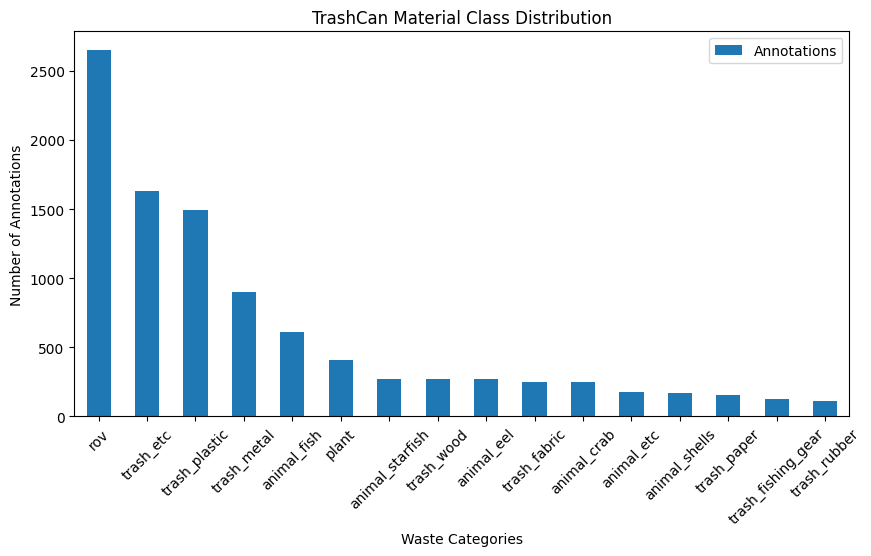

In [ ]:
# Display category distribution
class_distribution.plot(
    x='Category',
    y='Annotations',
    kind='bar',
    figsize=(10, 5),
    title='TrashCan Material Class Distribution'
)

plt.xlabel('Waste Categories')
plt.ylabel('Number of Annotations')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Define the 8 waste categories

waste_categories = [
    'trash_etc', 'trash_plastic', 'trash_metal', 'trash_wood',
    'trash_fabric', 'trash_paper', 'trash_fishing_gear', 'trash_rubber'
]

# Get category IDs

waste_category_ids = [
    c['id'] for c in train_data['categories']
    if c['name'] in waste_categories
]

# Filter annotations

train_annotations = [a for a in train_data['annotations'] if a['category_id'] in waste_category_ids]
val_annotations = [a for a in val_data['annotations'] if a['category_id'] in waste_category_ids]

# Display results

print("Waste categories:", len(waste_category_ids))
print("Training annotations:", len(train_annotations))
print("Validation annotations:", len(val_annotations))

Waste categories: 8
Training annotations: 4933
Validation annotations: 1281


In [ ]:
# Create classification labels
category_mapping = {
    category_id: index
    for index, category_id in enumerate(waste_category_ids)
}

train_labels = [category_mapping[a['category_id']] for a in train_annotations]
val_labels = [category_mapping[a['category_id']] for a in val_annotations]

print("Category mapping:", category_mapping)
print("Training labels:", len(train_labels))
print("Validation labels:", len(val_labels))

Category mapping: {9: 0, 10: 1, 11: 2, 12: 3, 13: 4, 14: 5, 15: 6, 16: 7}
Training labels: 4933
Validation labels: 1281


Prepare image datasets

In [ ]:
from keras.utils import image_dataset_from_directory

train_dataset = image_dataset_from_directory(
    balanced_train_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical',
    seed=42
)

val_dataset = image_dataset_from_directory(
    val_crop_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical',
    shuffle=False
)

epochs = 70

Found 2112 files belonging to 8 classes.
Found 1281 files belonging to 8 classes.


Build the MobileNetV2 classification model

In [ ]:
from keras import models, layers
from keras.applications import MobileNetV2

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build our classification model
network = models.Sequential()

network.add(layers.Input(shape=(224, 224, 3)))

# Data augmentation
network.add(layers.RandomFlip("horizontal"))
network.add(layers.RandomRotation(0.05))
network.add(layers.RandomZoom(0.05))

# MobileNetV2 preprocessing
network.add(layers.Rescaling(1./127.5, offset=-1))

# Pretrained MobileNetV2
network.add(base_model)

# Classification layers
network.add(layers.GlobalAveragePooling2D())
network.add(layers.Dense(128, activation='relu'))
network.add(layers.Dropout(0.3))

# 8 waste categories
network.add(layers.Dense(8, activation='softmax'))

network.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,984 (9.24 MB)

 Trainable params: 165,000 (644.53 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Compile and train the classification model

In [ ]:
from keras import callbacks
from keras.optimizers import Adam

# Callbacks
callbacks_phase = [
    callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/waste_cnn.keras",
        save_best_only=True,
        monitor="val_loss"
    ),

    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    )
]

# Compile model
network.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history_phase = network.fit(
    train_dataset,
    epochs=epochs,
    validation_data=val_dataset,
    callbacks=callbacks_phase
)

Epoch 1/70
66/66 ━━━━━━━━━━━━━━━━━━━━ 214s 3s/step - accuracy: 0.4763 - loss: 1.4783 - val_accuracy: 0.5113 - val_loss: 1.3281
Epoch 2/70
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.6473 - loss: 1.0126 - val_accuracy: 0.5129 - val_loss: 1.2944
Epoch 3/70
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.7211 - loss: 0.8191 - val_accuracy: 0.5199 - val_loss: 1.2773
Epoch 4/70
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.7438 - loss: 0.7312 - val_accuracy: 0.5379 - val_loss: 1.2677
Epoch 5/70
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.7841 - loss: 0.6275 - val_accuracy: 0.5706 - val_loss: 1.1979
Epoch 6/70
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.8016 - loss: 0.5753 - val_accuracy: 0.5543 - val_loss: 1.2753
Epoch 7/70
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.8177 - loss: 0.5299 - val_accuracy: 0.5660 - val_loss: 1.2208
Epoch 8/70
66/66 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.8314 - loss: 0.4861 - val_accuracy: 0.5589 - v

Visualize training performance

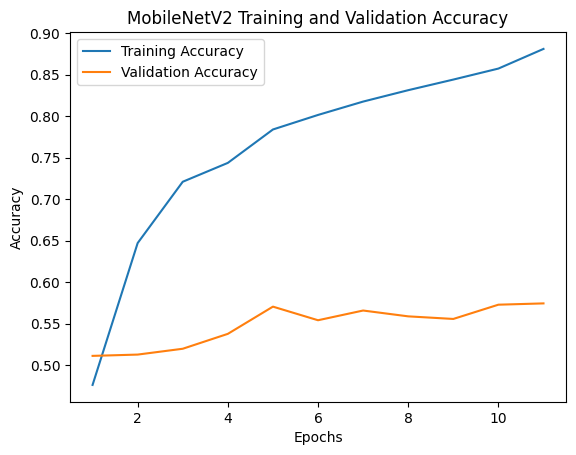

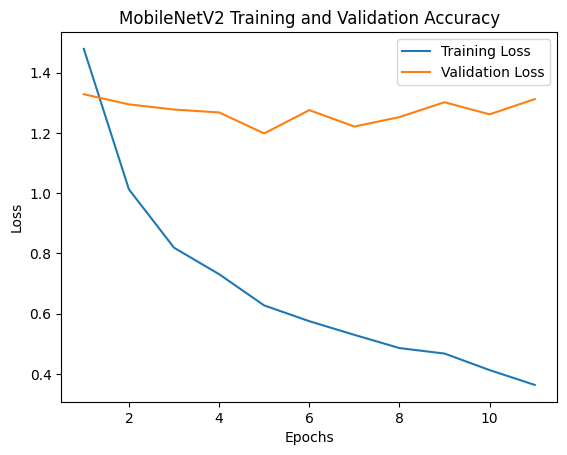

In [ ]:
import matplotlib.pyplot as plt

acc = history_phase.history['accuracy']
val_acc = history_phase.history['val_accuracy']

loss = history_phase.history['loss']
val_loss = history_phase.history['val_loss']

epochs_range = range(1, len(acc) + 1)

# Accuracy plot
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title('MobileNetV2 Training and Validation Accuracy')
plt.show()

# Loss plot
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title('MobileNetV2 Training and Validation Loss')
plt.legend()
plt.show()

Evaluate the first classification model

In [ ]:
from keras import models

best_model = models.load_model(
    "/content/drive/MyDrive/waste_cnn.keras"
)

In [ ]:
print("Waste Classification Evaluation:")
print(best_model.evaluate(val_dataset))

Waste Classification Evaluation:
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.5706 - loss: 1.1979
[1.1979085206985474, 0.5706479549407959]


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

# Get actual labels
y_true = np.concatenate([
    np.argmax(labels, axis=1)
    for images, labels in val_dataset
])

# Get predictions
predicted = best_model.predict(val_dataset)
y_pred = np.argmax(predicted, axis=1)

# Display classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=val_dataset.class_names,
    digits=4,
    zero_division=0
))

41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step
                    precision    recall  f1-score   support

         trash_etc     0.5368    0.6773    0.5989       409
      trash_fabric     0.9524    0.5128    0.6667        39
trash_fishing_gear     0.9000    0.3103    0.4615        29
       trash_metal     0.8421    0.4638    0.5981        69
       trash_paper     0.5820    0.5882    0.5851       374
     trash_plastic     0.5733    0.6418    0.6056        67
      trash_rubber     0.5056    0.6522    0.5696        69
        trash_wood     0.5519    0.3778    0.4485       225

          accuracy                         0.5706      1281
         macro avg     0.6805    0.5280    0.5668      1281
      weighted avg     0.5902    0.5706    0.5662      1281



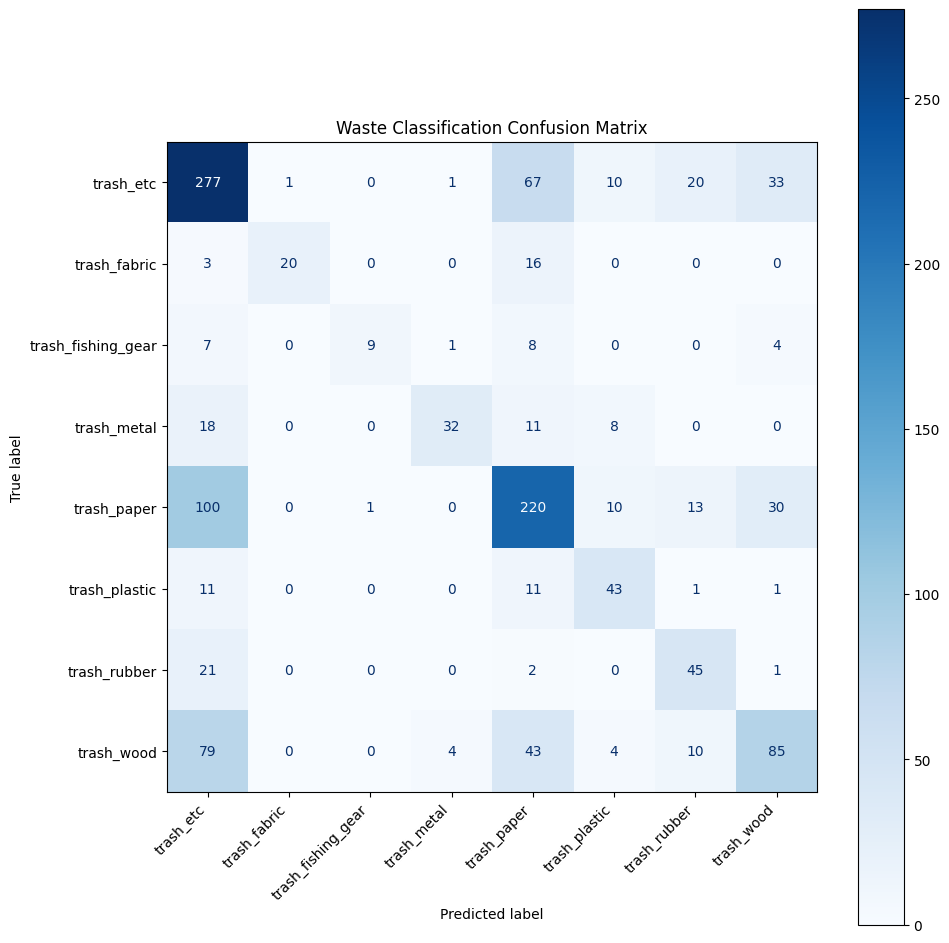

In [ ]:
# Create confusion matrix

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=val_dataset.class_names
)

fig, ax = plt.subplots(figsize=(10, 10))

disp.plot(ax=ax, values_format='d', cmap='Blues')

plt.xticks(rotation=45, ha='right')
plt.title('Waste Classification Confusion Matrix')
plt.tight_layout()
plt.show()

Fine-tune MobileNetV2

In [ ]:
from keras import models, layers, callbacks
from keras.optimizers import Adam

# Load original MobileNetV2 model
best_model = models.load_model(
    '/content/drive/MyDrive/waste_cnn.keras'
)

# Get MobileNetV2
base_model = best_model.get_layer('mobilenetv2_1.00_224')

# Unfreeze MobileNetV2
base_model.trainable = True

# Freeze all except the last 35 layers
for layer in base_model.layers[:-35]:
    layer.trainable = False

# Keep Batch Normalization frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Compile with a low learning rate
best_model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Save the best model and stop if it stops improving
callbacks_phase2 = [
    callbacks.ModelCheckpoint(
        '/content/drive/MyDrive/mobilenet_phase2.keras',
        save_best_only=True,
        monitor='val_loss'
    ),
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=6,
        restore_best_weights=True
    )
]

# Fine-tune the model
history_phase2 = best_model.fit(
    train_dataset,
    epochs=30,
    validation_data=val_dataset,
    callbacks=callbacks_phase2
)


Epoch 1/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 16s 136ms/step - accuracy: 0.8092 - loss: 0.5533 - val_accuracy: 0.5730 - val_loss: 1.2057
Epoch 2/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.8305 - loss: 0.4885 - val_accuracy: 0.5628 - val_loss: 1.2267
Epoch 3/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.8404 - loss: 0.4733 - val_accuracy: 0.5816 - val_loss: 1.2557
Epoch 4/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.8504 - loss: 0.4310 - val_accuracy: 0.5566 - val_loss: 1.2665
Epoch 5/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.8570 - loss: 0.4129 - val_accuracy: 0.5870 - val_loss: 1.2157
Epoch 6/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.8561 - loss: 0.4079 - val_accuracy: 0.5761 - val_loss: 1.2377
Epoch 7/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.8660 - loss: 0.3980 - val_accuracy: 0.5863 - val_loss: 1.2461


Evaluate the final fine-tuned model using the same validation dataset and metrics.

In [ ]:
print("Phase 2 Evaluation:")
best_model.evaluate(val_dataset)

Phase 2 Evaluation:
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.5730 - loss: 1.2057


[1.2056596279144287, 0.5729898810386658]

In [ ]:
import numpy as np
from sklearn.metrics import classification_report

# Actual labels
y_true = np.concatenate([
    np.argmax(labels, axis=1)
    for images, labels in val_dataset
])

# Predicted labels
predicted = best_model.predict(val_dataset)
y_pred = np.argmax(predicted, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=val_dataset.class_names,
    digits=4,
    zero_division=0
))

41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step
                    precision    recall  f1-score   support

         trash_etc     0.5727    0.6064    0.5891       409
      trash_fabric     0.7586    0.5641    0.6471        39
trash_fishing_gear     0.6250    0.3448    0.4444        29
       trash_metal     0.6379    0.5362    0.5827        69
       trash_paper     0.6166    0.5374    0.5743       374
     trash_plastic     0.5217    0.7164    0.6038        67
      trash_rubber     0.5269    0.7101    0.6049        69
        trash_wood     0.5085    0.5289    0.5185       225

          accuracy                         0.5730      1281
         macro avg     0.5960    0.5681    0.5706      1281
      weighted avg     0.5795    0.5730    0.5721      1281



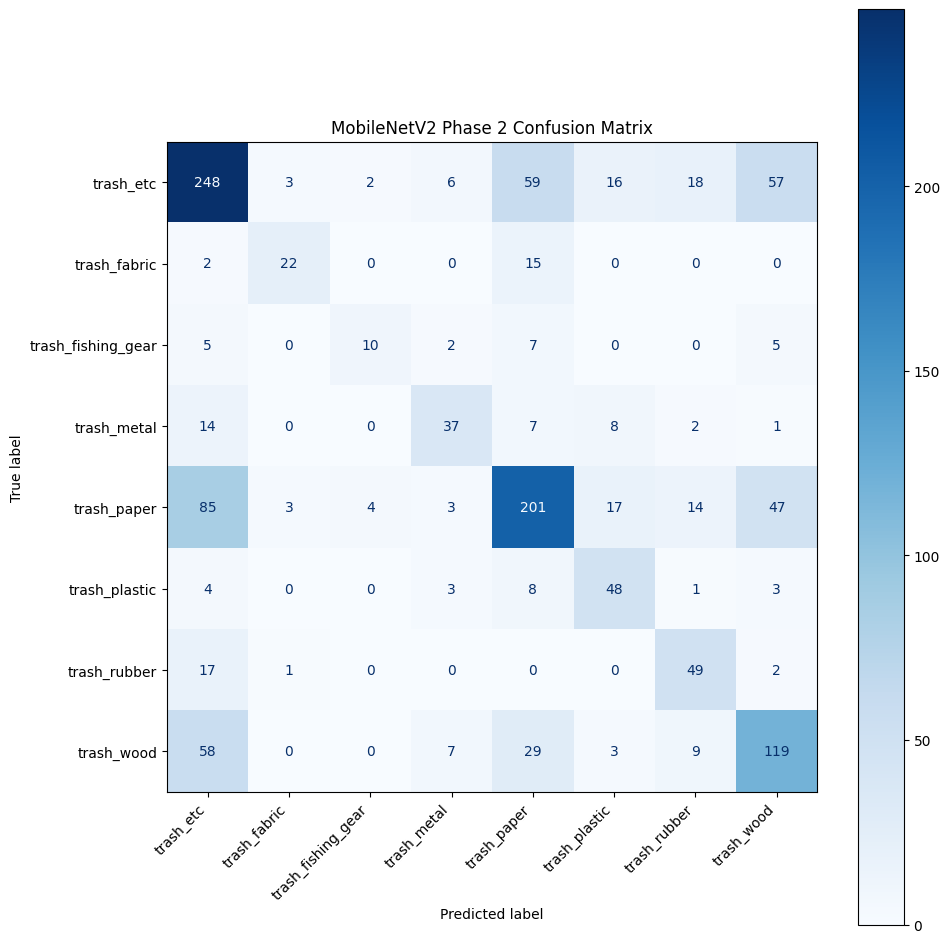

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=val_dataset.class_names
)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, values_format='d', cmap='Blues')

plt.xticks(rotation=45, ha='right')
plt.title('MobileNetV2 Phase 2 Confusion Matrix')
plt.tight_layout()
plt.show()

Save classification model files

In [ ]:
import json
from google.colab import files

print(val_dataset.class_names)   # the label order, keep this
with open('class_names.json', 'w') as f:
    json.dump(val_dataset.class_names, f)

files.download('/content/drive/MyDrive/mobilenet_phase2.keras')
files.download('class_names.json')

['trash_etc', 'trash_fabric', 'trash_fishing_gear', 'trash_metal', 'trash_paper', 'trash_plastic', 'trash_rubber', 'trash_wood']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Localisation and Segmentation

Load COCO annotations

In [ ]:
import json

with open(train_json, 'r') as f:
    coco = json.load(f)

for category in coco['categories']:
    print(category['id'], category['name'])

1 rov
2 plant
3 animal_fish
4 animal_starfish
5 animal_shells
6 animal_crab
7 animal_eel
8 animal_etc
9 trash_etc
10 trash_fabric
11 trash_fishing_gear
12 trash_metal
13 trash_paper
14 trash_plastic
15 trash_rubber
16 trash_wood


In [ ]:
#!pip install pycocotools

Use the annotation indexes from the balanced classification dataset

In [ ]:
selected_indexes = []

for category in waste_categories:
    folder = os.path.join(balanced_train_dir, category)

    for filename in os.listdir(folder):
        if filename.endswith('.jpg'):
            index = int(filename.replace('.jpg', ''))
            selected_indexes.append(index)

selected_annotations = [
    train_annotations[i] for i in selected_indexes
]

print("Selected annotations:", len(selected_annotations))

Selected annotations: 2112


Create a data.yaml file that tells YOLO where the training and validation images are located and defines the eight waste categories.

In [ ]:
# Create YOLO data.yaml file

# Load existing YOLO configuration file
yaml_path = '/content/drive/MyDrive/dataset/waste_yolo/data.yaml'

print("YOLO configuration file loaded!")
print(yaml_path)

YOLO configuration file created!
/content/drive/MyDrive/dataset/waste_yolo/data.yaml


In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 65.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
GPU available: True
GPU: NVIDIA L4


Load the pretrained YOLO11n-seg model and train it using the prepared dataset.

In [ ]:
from ultralytics import YOLO

model = YOLO('yolo11n-seg.pt')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
results = model.train(
    data='/content/drive/MyDrive/dataset/waste_yolo/data.yaml',
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    name='underwater_waste_segmentation'
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/dataset/waste_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=underwater_waste_segmentation, n

Download the best-performing weights for use in the Streamlit application.

In [ ]:
from google.colab import files

files.download('/content/runs/segment/underwater_waste_segmentation/weights/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Limitations & Ethical Considerations
- Bias and Fairness: The dataset may not represent all underwater environments and waste types equally, which could affect the model's ability to recognize certain waste categories.
- Data Leakage: Care must be taken to ensure that training and validation images are separated properly to prevent the model from learning from images it has already seen.
- Compute Constraints: Training deep learning models, particularly YOLO11n-seg and MobileNetV2, requires significant computing resources. GPU availability, memory limitations, and training time may affect model performance and experimentation.
- Model Limitations: The models may produce incorrect classifications, missed detections, or inaccurate segmentation masks, especially when objects are small, overlapping, damaged, or difficult to distinguish.